<a href="https://colab.research.google.com/github/FARZANA-HOSSAIN-MIMI/spam-detection-updated/blob/main/SMS_Spam_SVM_Improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification — Improved SVM and Model Comparison
Dataset: [SMS Spam Collection (Kaggle)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

**What was improved compared with the original notebook**

| # | Original | This version | Why |
|---|----------|--------------|-----|
| 1 | Digits, currency symbols and URLs were deleted | They are replaced by tokens (`moneytoken`, `numtoken`, `urltoken`, ...) | Spam is full of prices, phone numbers and links, so deleting them removed the best signals |
| 2 | Word TF-IDF only | Word TF-IDF **+ character n-gram TF-IDF** | Catches obfuscated words such as `fr33`, `txt`, `claim!!` |
| 3 | `class_weight` not set (spam recall was only ~0.89) | `class_weight='balanced'` | Only ~13% of messages are spam |
| 4 | Grid search scored on accuracy | Grid search scored on **F1** | Accuracy is misleading on imbalanced data |
| 5 | The tuned model was never evaluated on the test set | Held-out test set used **once**, at the end | Honest final numbers |
| 6 | Cross-validation on the whole dataset | Cross-validation on the **training set only** | Avoids data leakage into the test set |
| 7 | Only one model | 7 models compared with repeated cross-validation | Shows the choice of model is evidence-based |
| 8 | ROC / confusion-matrix imports never used | Confusion matrices, ROC and PR curves, error analysis | Completes the evaluation |

## 1. Setup

In [ ]:
# Install (Colab already has most of these)
!pip -q install wordcloud nltk scikit-learn lightgbm

In [ ]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import joblib
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

True

## 2. Load the dataset
Upload `spam.csv` (downloaded from Kaggle) when prompted. Outside Colab, the cell falls back to a local `spam.csv`.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]   # works whatever the file is called
except ImportError:
    DATA_FILE = "spam.csv"                 # running locally

df = pd.read_csv(DATA_FILE, encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "message"]
print("Loaded:", DATA_FILE, df.shape)

Loaded: spam.csv (5572, 2)


In [ ]:
print(df.info())
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None
Missing values:
 label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


The dataset contains many exact duplicate messages. They are removed **before** splitting, so the same message can never appear in both train and test.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)      # ham = 0, spam = 1
print("After removing duplicates:", df.shape)
print(df["label"].value_counts(normalize=True).round(3))

After removing duplicates: (5169, 3)
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis

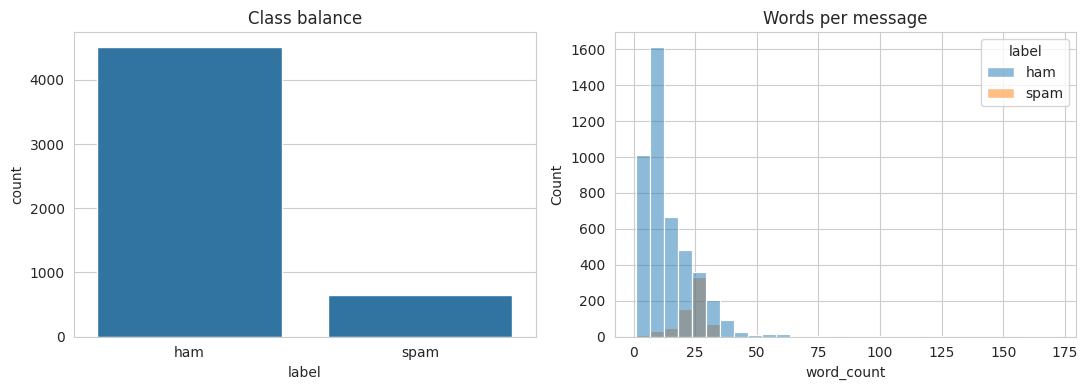

       char_count  word_count
label                        
ham          70.5        14.1
spam        137.9        23.7


In [ ]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="label", ax=ax[0]);  ax[0].set_title("Class balance")
sns.histplot(data=df, x="word_count", hue="label", bins=30, ax=ax[1]);  ax[1].set_title("Words per message")
plt.tight_layout(); plt.show()

print(df.groupby("label")[["char_count", "word_count"]].mean().round(1))

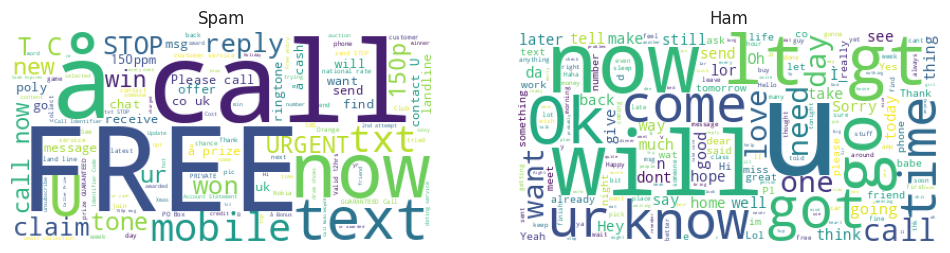

In [ ]:
spam_text = " ".join(df[df.label == "spam"].message)
ham_text  = " ".join(df[df.label == "ham"].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(WordCloud(background_color="white").generate(spam_text)); plt.axis("off"); plt.title("Spam")
plt.subplot(1, 2, 2); plt.imshow(WordCloud(background_color="white").generate(ham_text));  plt.axis("off"); plt.title("Ham")
plt.show()

## 4. Preprocessing
Two cleaning functions are kept so the comparison is fair:
* `clean_original` — the original approach (deletes digits and symbols)
* `clean_text` — **improved**: replaces money, long numbers (phone numbers / short codes), numbers, URLs and e-mails with placeholder tokens instead of deleting them

In [ ]:
stop_words = set(stopwords.words("english"))
lemm = WordNetLemmatizer()

def clean_original(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    return " ".join(lemm.lemmatize(w) for w in text.split() if w not in stop_words)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " urltoken ", text)
    text = re.sub(r"\S+@\S+", " emailtoken ", text)
    text = re.sub(r"[£$€]\s?\d+[\d,.]*", " moneytoken ", text)   # prices / prizes
    text = re.sub(r"\b\d{5,}\b", " longnumtoken ", text)          # phone numbers, short codes
    text = re.sub(r"\d+", " numtoken ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(lemm.lemmatize(w) for w in text.split() if w not in stop_words)

df["clean_original"] = df["message"].apply(clean_original)
df["clean_text"] = df["message"].apply(clean_text)

for i in [2, 8, 11]:
    print("RAW     :", df.message[i])
    print("ORIGINAL:", df.clean_original[i])
    print("IMPROVED:", df.clean_text[i], "\n")

RAW     : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
ORIGINAL: free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply
IMPROVED: free entry numtoken wkly comp win fa cup final tkts numtoken st may numtoken text fa longnumtoken receive entry question std txt rate c apply numtoken numtoken 

RAW     : WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
ORIGINAL: winner valued network customer selected receivea å£ prize reward claim call claim code kl valid hour
IMPROVED: winner valued network customer selected receivea moneytoken prize reward claim call longnumtoken claim code kl numtoken valid numtoken hour 

RAW     : SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ T

## 5. Train / test split
The test set (20%) is locked away and used **only once**, at the end.

In [ ]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df["y"])
X_train, y_train = train_df[["message", "clean_original", "clean_text"]], train_df["y"]
X_test,  y_test  = test_df[["message", "clean_original", "clean_text"]],  test_df["y"]
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Spam share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (4135, 3)  Test: (1034, 3)
Spam share  train: 0.126  test: 0.127


## 6. Baseline — the original SVM
Reproduced exactly as in the original notebook (TF-IDF on 5000 word 1-2 grams + `LinearSVC`), now evaluated on the test set.

In [ ]:
results = []      # collects test-set metrics for every model we evaluate

def evaluate(name, model, X, y):
    pred = model.predict(X)
    score = model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]
    row = {"model": name,
           "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
           "recall": recall_score(y, pred),     "f1": f1_score(y, pred),
           "roc_auc": roc_auc_score(y, score),  "pr_auc": average_precision_score(y, score)}
    results.append(row)
    print(classification_report(y, pred, target_names=["ham", "spam"], digits=3))
    return pred, score

baseline = Pipeline([
    ("features", ColumnTransformer([("w", TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), "clean_original")])),
    ("clf", LinearSVC()),
])
baseline.fit(X_train, y_train)
base_pred, base_score = evaluate("Original SVM", baseline, X_test, y_test)

              precision    recall  f1-score   support

         ham      0.984     0.998     0.991       903
        spam      0.983     0.885     0.932       131

    accuracy                          0.984      1034
   macro avg      0.983     0.942     0.961      1034
weighted avg      0.984     0.984     0.983      1034



## 7. Improved features + tuned SVM
* word 1-2 grams on the improved text **plus** character 2-5 grams on the raw message
* `sublinear_tf=True` (dampens very frequent terms)
* `class_weight='balanced'`
* `C` tuned with 5-fold CV on the **training set**, scored on **F1**

In [ ]:
def make_features():
    return ColumnTransformer([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "clean_text"),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "message"),
    ])

svm_pipe = Pipeline([("features", make_features()),
                     ("clf", LinearSVC(class_weight="balanced"))])

grid = GridSearchCV(svm_pipe, {"clf__C": [0.1, 0.3, 1, 3]}, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV F1     : %.4f" % grid.best_score_)

improved_svm = grid.best_estimator_
svm_pred, svm_score = evaluate("Improved SVM", improved_svm, X_test, y_test)

Best parameters: {'clf__C': 0.1}
Best CV F1     : 0.9644


              precision    recall  f1-score   support

         ham      0.992     0.998     0.995       903
        spam      0.984     0.947     0.965       131

    accuracy                          0.991      1034
   macro avg      0.988     0.972     0.980      1034
weighted avg      0.991     0.991     0.991      1034



## 8. Comparing different models
Every model uses the **same improved features** and the **same training data**.
Repeated stratified 5-fold CV (2 repeats) is used because a single split of ~1000 test messages is noisy (one message = 0.1%).
The test set is not touched here.

In [ ]:
calibrated_svm = lambda: CalibratedClassifierCV(LinearSVC(C=1, class_weight="balanced"), cv=3)
logreg         = lambda: LogisticRegression(C=30, class_weight="balanced", max_iter=3000)

candidates = {
    "Original SVM":        baseline,
    "Improved SVM":        Pipeline([("features", make_features()), ("clf", LinearSVC(C=1, class_weight="balanced"))]),
    "Logistic Regression": Pipeline([("features", make_features()), ("clf", logreg())]),
    "Complement NB":       Pipeline([("features", make_features()), ("clf", ComplementNB(alpha=0.3))]),
    "Random Forest":       Pipeline([("features", make_features()), ("clf", RandomForestClassifier(
                               n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    "LightGBM":            Pipeline([("features", make_features()), ("clf", lgb.LGBMClassifier(
                               n_estimators=300, learning_rate=0.05, class_weight="balanced",
                               verbose=-1, random_state=RANDOM_STATE))]),
    "Soft-Voting Ensemble": Pipeline([("features", make_features()), ("clf", VotingClassifier(
                               [("svm", calibrated_svm()), ("lr", logreg()), ("nb", MultinomialNB(alpha=0.05))],
                               voting="soft"))]),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in candidates.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{m: r[f"test_{m}"].mean() for m in scoring}, "f1_std": r["test_f1"].std()})
    print(f"done: {name}")

cv_table = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
cv_table.round(4)

done: Original SVM


done: Improved SVM


done: Logistic Regression


done: Complement NB


done: Random Forest


done: LightGBM


done: Soft-Voting Ensemble


,accuracy,precision,recall,f1,roc_auc,f1_std
model,,,,,,
Logistic Regression,0.9906,0.9729,0.9521,0.9622,0.9948,0.0068
Soft-Voting Ensemble,0.9906,0.9765,0.9483,0.9620,0.9949,0.0077
Improved SVM,0.9902,0.9774,0.9445,0.9605,0.9952,0.0073
LightGBM,0.9872,0.9887,0.9090,0.9469,0.9918,0.0151
Complement NB,0.9865,0.9777,0.9138,0.9445,0.9858,0.0154
Random Forest,0.9791,0.9978,0.8362,0.9096,0.9939,0.0160
Original SVM,0.9778,0.9696,0.8506,0.9058,0.9823,0.0233


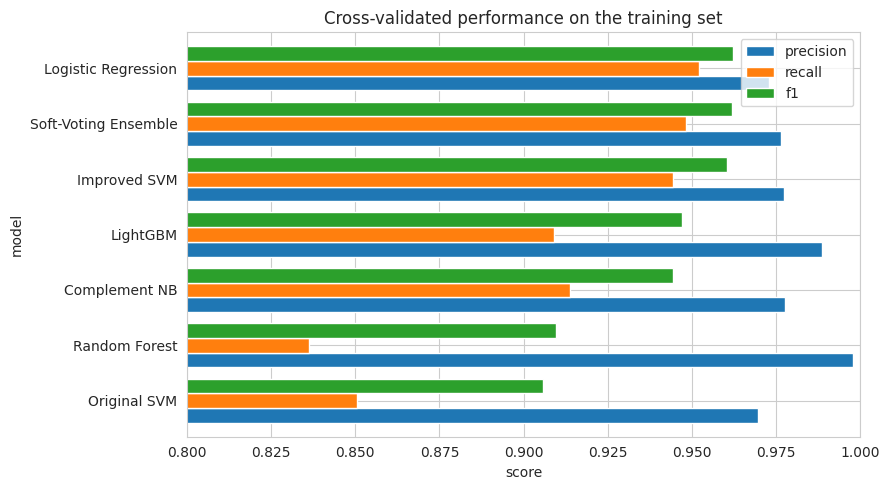

In [ ]:
ax = cv_table[["precision", "recall", "f1"]].sort_values("f1").plot.barh(figsize=(9, 5), width=0.8)
ax.set_xlim(0.80, 1.0); ax.set_title("Cross-validated performance on the training set"); ax.set_xlabel("score")
plt.tight_layout(); plt.show()

**Reading the table:** the gap between *Original SVM* and every other well-built model is large (≈ 4 F1 points, mostly extra spam caught),
while the strongest models — improved SVM, logistic regression and the ensemble — are within about one standard deviation of each other (`f1_std`).
The **soft-voting ensemble** (calibrated SVM + logistic regression + naive Bayes) is used as the final model because it matches the best single model on every metric, is not tied to one set of hyper-parameters, and outputs a spam *probability*.

## 9. Final model — one-time evaluation on the test set

In [ ]:
final_model = candidates["Soft-Voting Ensemble"]
final_model.fit(X_train, y_train)
final_pred, final_score = evaluate("Soft-Voting Ensemble", final_model, X_test, y_test)

              precision    recall  f1-score   support

         ham      0.992     0.998     0.995       903
        spam      0.984     0.947     0.965       131

    accuracy                          0.991      1034
   macro avg      0.988     0.972     0.980      1034
weighted avg      0.991     0.991     0.991      1034



In [ ]:
test_table = pd.DataFrame(results).set_index("model").round(4)
test_table

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Original SVM,0.9836,0.9831,0.8855,0.9317,0.9959,0.9818
Improved SVM,0.9913,0.9841,0.9466,0.9650,0.9986,0.9931
Soft-Voting Ensemble,0.9913,0.9841,0.9466,0.9650,0.9988,0.9939


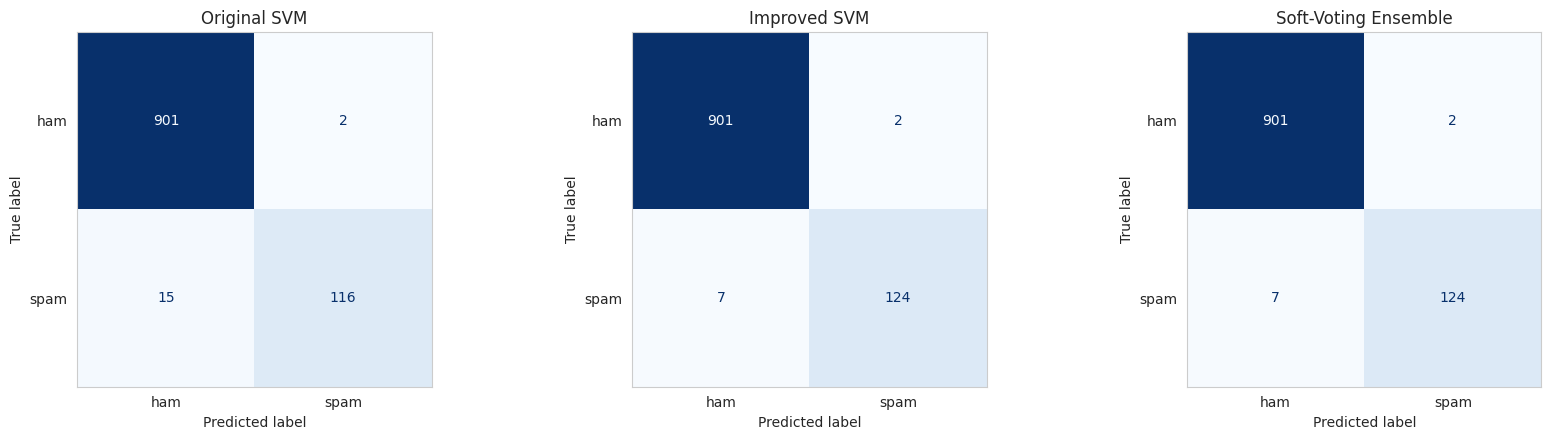

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (title, pred) in zip(ax, [("Original SVM", base_pred), ("Improved SVM", svm_pred), ("Soft-Voting Ensemble", final_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(title); a.grid(False)
plt.tight_layout(); plt.show()

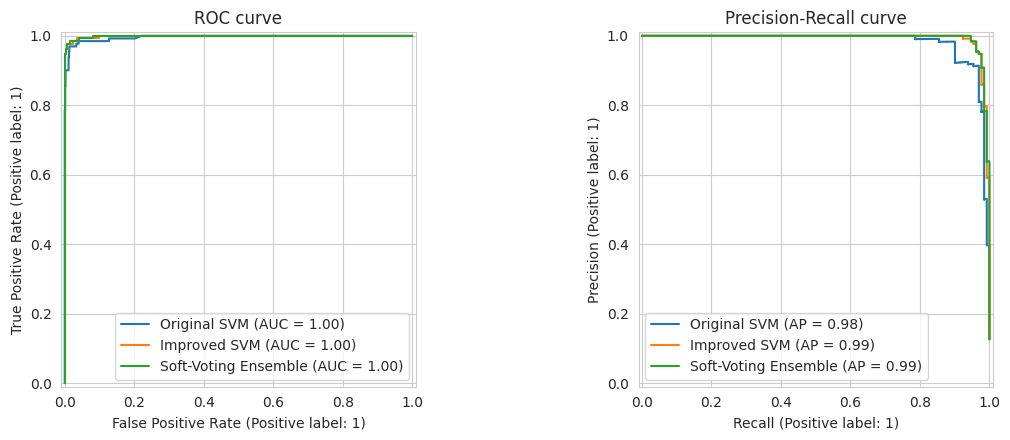

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, score in [("Original SVM", base_score), ("Improved SVM", svm_score), ("Soft-Voting Ensemble", final_score)]:
    RocCurveDisplay.from_predictions(y_test, score, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=ax[1])
ax[0].set_title("ROC curve"); ax[1].set_title("Precision-Recall curve")
plt.tight_layout(); plt.show()

## 10. Error analysis — what does the final model still get wrong?

In [ ]:
errors = test_df.loc[final_pred != y_test.values, ["message", "label"]].copy()
errors["predicted"] = np.where(final_pred[final_pred != y_test.values] == 1, "spam", "ham")
errors["spam_prob"] = final_model.predict_proba(X_test)[final_pred != y_test.values, 1].round(3)
print(f"{len(errors)} misclassified out of {len(test_df)} test messages\n")
pd.set_option("display.max_colwidth", 140)
errors.rename(columns={"label": "actual"})

9 misclassified out of 1034 test messages



,message,actual,predicted,spam_prob
660,SMS. ac sun0819 posts HELLO:\You seem cool,spam,ham,0.408
2888,Your bill at 3 is å£33.65 so thats not bad!,ham,spam,0.569
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,spam,ham,0.384
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",spam,ham,0.044
3330,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. ...",spam,ham,0.269
3586,Yep then is fine 7.30 or 8.30 for ice age.,ham,spam,0.566
5062,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,ham,0.120
1812,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,spam,ham,0.020
2641,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...,spam,ham,0.241


## 11. Save the model and try it on new messages

In [ ]:
joblib.dump(final_model, "spam_classifier.joblib")

def predict_sms(text, model=final_model):
    row = pd.DataFrame({"message": [text], "clean_original": [clean_original(text)], "clean_text": [clean_text(text)]})
    p = model.predict_proba(row)[0, 1]
    return f"{'Spam' if p >= 0.5 else 'Ham'}  (spam probability = {p:.2f})"

tests = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! Your mobile number has won a £2000 prize. Call 09061701461 to claim.",
    "Can you send me the notes from today's lecture?",
    "FreeMsg: Txt WIN to 80086 now to get your free ringtone!",
]
for t in tests:
    print(predict_sms(t), "<-", t)

Spam  (spam probability = 0.63) <- Congratulations! You have won a free iPhone. Click here now.
Ham  (spam probability = 0.00) <- Hi, are we meeting tomorrow at 3 PM?
Spam  (spam probability = 1.00) <- URGENT! Your mobile number has won a £2000 prize. Call 09061701461 to claim.
Ham  (spam probability = 0.02) <- Can you send me the notes from today's lecture?
Spam  (spam probability = 1.00) <- FreeMsg: Txt WIN to 80086 now to get your free ringtone!


## 12. Conclusions

**Results on the held-out test set (1,034 messages, 131 spam) in the run saved in this notebook**

| | Original SVM | Final model (soft-voting ensemble) |
|---|---|---|
| Accuracy | 0.984 | **0.991** |
| Spam recall | 0.886 | **0.947** |
| Spam precision | 0.983 | 0.984 |
| F1 (spam) | 0.932 | **0.965** |
| Spam messages missed | 15 | **7** |
| Total errors | 17 | **9** |

**Main findings**
1. **The biggest improvement came from the features, not from the classifier.** Keeping prices, phone numbers and links as tokens, adding character n-grams and using `class_weight='balanced'` cut missed spam from 15 to 7 messages while keeping precision unchanged.
2. **Changing the model family gave no further significant gain.** Logistic regression, the tuned SVM and the soft-voting ensemble are statistically tied (their cross-validated F1 differ by less than one standard deviation). Tree-based models (Random Forest, LightGBM) and Naive Bayes were clearly worse at catching spam.
3. **The ensemble was chosen as the final model** because it matches the best single model on every metric and also outputs a calibrated spam *probability*, which is useful for choosing a stricter or more lenient threshold in practice.
4. **Remaining errors** are mostly spam written like ordinary chat (a joke, a news headline, a quiz) and a few genuine messages that mention bills or prices. These are hard for any bag-of-words model.

**Limitations and next steps**
* Only 653 unique spam messages exist in the training data, and the test set has just 131, so one message changes recall by about 0.8 points; small differences between models should not be over-interpreted.
* The data is older, mostly UK-English SMS. A model trained on it may not transfer to modern spam without retraining.
* A fine-tuned transformer (e.g. DistilBERT) is the most promising way to improve further because it understands context, but it needs a GPU and is much heavier than the SVM.